# Restoration demo: one good case, one bad case

A quick demo for the progress presentation (slide 4). It loads only the frozen ResNet-50 (no depth model), so it runs in well under a minute.

For each example: **clean image → damaged image → classical restoration (oracle: told the true damage) → frozen ResNet-50**.

- **Good:** *brighten* is a reversible transform. The object is still in the pixels, so restoration can undo it.
- **Bad:** *Gaussian noise* destroys fine detail. The denoiser has to estimate what was there, and it wipes out the texture ResNet relies on.

Both images are from the full run and are **ImageNet validation images** (`ILSVRC2012_val_*`), so ResNet-50 never trained on them.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make `src/bolero` importable from wherever the notebook is opened.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "bolero").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from bolero.classifier import FrozenClassifier
from bolero.config import IMAGENETTE_CLASSES, IMAGENETTE_INDEX, SEED, find_imagenette_root
from bolero.data import load_image
from bolero.perturbations import PERTURBATIONS, rng_for
from bolero.restoration import PLANS, restore

classifier = FrozenClassifier()
root = find_imagenette_root()
print("device:", classifier.device, "| data:", root)

/opt/anaconda3/envs/projects/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 320/320 [00:00<00:00, 14763.48it/s]

device: mps | data: /Users/venkat/Desktop/Masters/ASU/Classes/ODM/clip_corruption_calibration/data/imagenette2-160


In [2]:
WNID = {name: wnid for wnid, name in IMAGENETTE_CLASSES.items()}

def short(label: str) -> str:
    return label.split(",")[0]

def run_example(image_id: str, class_name: str, perturbation: str, level: int = 3):
    wnid = WNID[class_name]
    clean = load_image(root / "val" / wnid / f"{image_id}.JPEG")
    # Same seeded damage as the full run, so the result matches results/restoration.
    damaged = PERTURBATIONS[perturbation](clean, level, rng=rng_for(image_id, perturbation, level, SEED))
    restored = restore(damaged, perturbation)

    images = [clean, damaged, restored]
    preds = classifier.predict(images, np.full(3, IMAGENETTE_INDEX[wnid]))
    plan = " + ".join(op.__name__ for op in PLANS[perturbation])
    titles = ["1. clean", f"2. {perturbation} (level {level})", f"3. restored ({plan})"]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
    for ax, im, title, idx, conf in zip(axes, images, titles, preds.index, preds.confidence):
        ok = idx == IMAGENETTE_INDEX[wnid]
        ax.imshow(im)
        ax.set_title(title, fontsize=11)
        ax.set_xlabel(f"{short(classifier.id2label[int(idx)])} ({conf:.0%}) {'✓' if ok else '✗'}",
                      color="tab:green" if ok else "tab:red", fontsize=12, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"True class: {class_name}", fontsize=13)
    plt.tight_layout(); plt.show()
    return images

## Good example: brightening (reversible)

Brightening squeezes every pixel toward white, but it keeps the pixels in the same order. The auto-levels stretch maps the range back out, so the evidence comes back and so does the label.

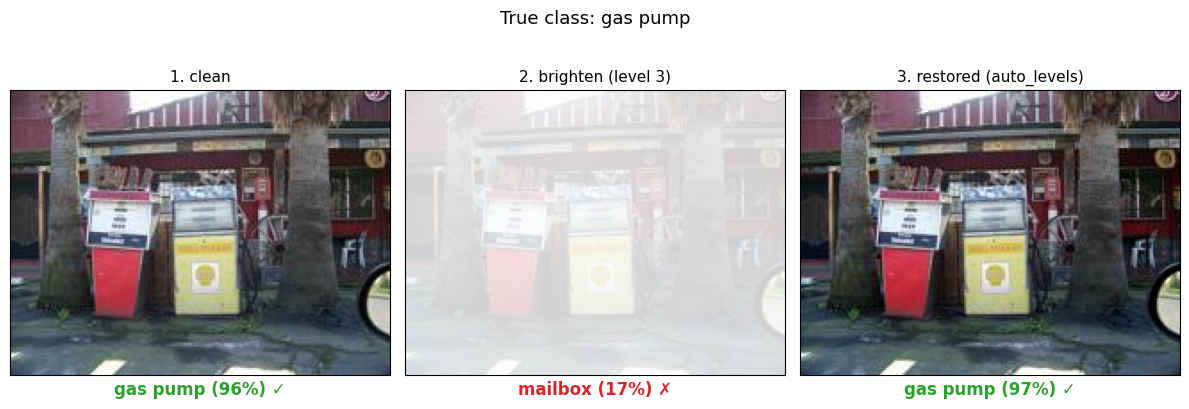

In [3]:
good = run_example("ILSVRC2012_val_00004860", "gas pump", "brighten")

## Bad example: Gaussian noise (information is lost)

Here the damaged image is still classified correctly, because ResNet can see the object's structure through the noise. The denoiser (non-local means) removes the noise **and** the fine texture with it. The smoothed result no longer looks like a chain saw to the model, so restoration turns a correct answer into a wrong one.

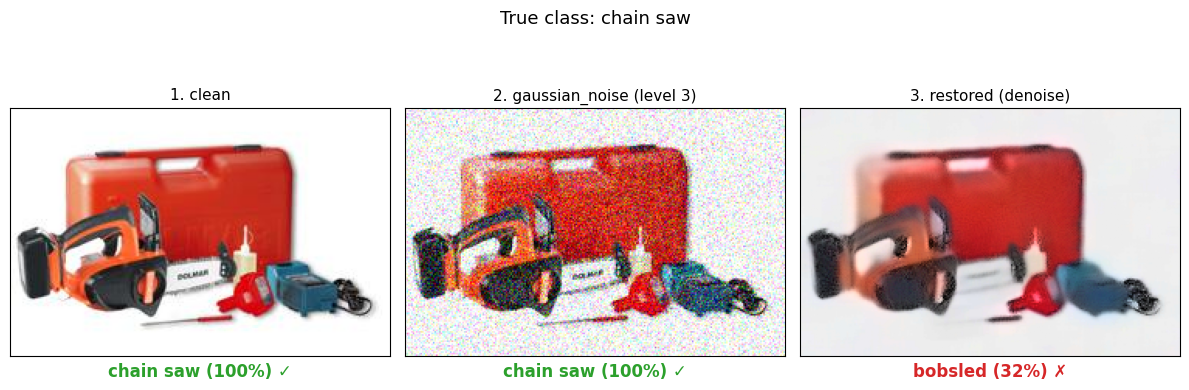

In [4]:
bad = run_example("ILSVRC2012_val_00011951", "chain saw", "gaussian_noise")

### Why: zoom in on the saw

In the noisy image the blade, its edge and the "DOLMAR" lettering are still visible under the noise, which is why ResNet still says *chain saw*. After denoising, the blade and the lettering are smeared away. What is left is a smooth orange-and-white shape, and ResNet reads that as a bobsled.

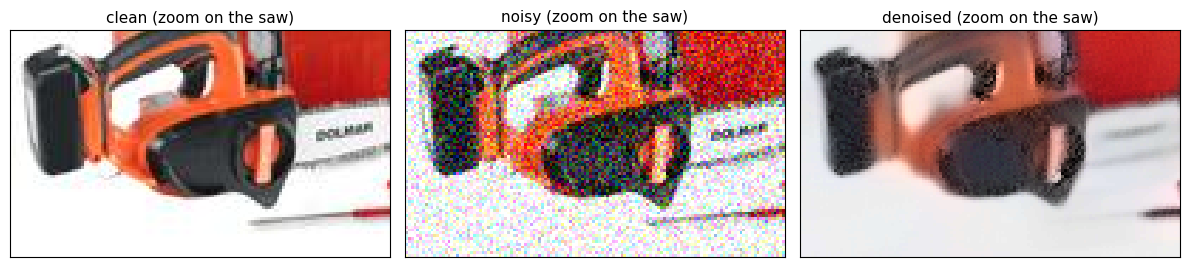

In [5]:
h, w = bad[0].shape[:2]
crop = (slice(int(h * 0.45), int(h * 0.95)), slice(0, int(w * 0.55)))  # the chain saw itself

fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, im, title in zip(axes, bad, ["clean", "noisy", "denoised"]):
    ax.imshow(im[crop], interpolation="nearest")
    ax.set_title(f"{title} (zoom on the saw)", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Takeaway

- **Reversible damage** (brighten, blur, inversion): the information is still in the image, and restoration recovers it. Gains are about +3 to +5 points across 500 images.
- **Destructive damage** (noise, missing regions): restoration has to estimate missing content and makes things worse, by up to −20 points.
- So the system needs to know **when not to restore**.

---
# Testing an outside image: `poly_test.webp`

A low-poly 3D render of a lighthouse. It isn't one of the 10 Imagenette classes, but ImageNet has a **"beacon, lighthouse"** class, so we use that as the true label.

The image is resized so its shorter side is 160 px, like the Imagenette-160 images, so the damage strengths mean the same thing as in our study.

true class: 437 beacon, lighthouse, beacon light, pharos


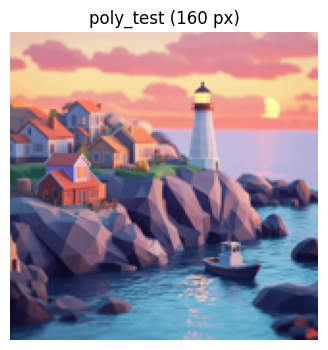

 72.2%  breakwater
 22.8%  beacon
  1.3%  promontory
  0.2%  studio couch
  0.2%  schooner


In [6]:
from PIL import Image

from bolero.restoration import restore

TEST_PATH = Path("/Users/venkat/Downloads/poly_test.webp")
TRUE_IDX = next(i for i, lab in classifier.id2label.items() if lab.startswith("beacon"))
print("true class:", TRUE_IDX, classifier.id2label[TRUE_IDX])

pil = Image.open(TEST_PATH).convert("RGB")
scale = 160 / min(pil.size)
pil = pil.resize((round(pil.width * scale), round(pil.height * scale)), Image.BICUBIC)
poly = np.asarray(pil, dtype=np.float32) / 255.0

def top5(image):
    import torch
    inputs = classifier.processor(images=[pil_from(image)], return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(classifier.model(pixel_values=inputs["pixel_values"].to(classifier.device)).logits.float(), -1)[0]
    conf, idx = probs.topk(5)
    return [(short(classifier.id2label[int(i)]), float(c)) for i, c in zip(idx.cpu(), conf.cpu())]

from bolero.data import to_pil as pil_from

plt.figure(figsize=(4, 4)); plt.imshow(poly); plt.axis("off"); plt.title("poly_test (160 px)"); plt.show()
for name, c in top5(poly):
    print(f"{c:6.1%}  {name}")

## Every damage type, with and without restoration

Level 3 (heavy). Only the 9 damage types that don't need a depth map, so the depth model isn't loaded. For each one: what ResNet says on the damaged image, then after the oracle restoration.

In [7]:
import pandas as pd

NO_DEPTH = [n for n, p in PERTURBATIONS.items() if not p.needs_depth]
LEVEL = 3

images, rows = {}, []
for name in NO_DEPTH:
    damaged = PERTURBATIONS[name](poly, LEVEL, rng=rng_for("poly_test", name, LEVEL, SEED))
    restored = restore(damaged, name)
    images[name] = (damaged, restored)

batch = [poly] + [im for name in NO_DEPTH for im in images[name]]
preds = classifier.predict(batch, np.full(len(batch), TRUE_IDX))
lab = lambda i: short(classifier.id2label[int(preds.index[i])])
mark = lambda i: "✓" if preds.index[i] == TRUE_IDX else "✗"

print(f"clean: {lab(0)} ({preds.confidence[0]:.0%}) {mark(0)} | lighthouse prob {preds.true_prob[0]:.0%}\n")
for k, name in enumerate(NO_DEPTH):
    d, r = 1 + 2 * k, 2 + 2 * k
    rows.append({
        "damage": name,
        "damaged → ResNet": f"{mark(d)} {lab(d)} ({preds.confidence[d]:.0%})",
        "restored → ResNet": f"{mark(r)} {lab(r)} ({preds.confidence[r]:.0%})",
        "lighthouse prob: damaged": f"{preds.true_prob[d]:.0%}",
        "lighthouse prob: restored": f"{preds.true_prob[r]:.0%}",
        "restoration": ("helped" if preds.true_prob[r] > preds.true_prob[d] + 0.05
                         else "hurt" if preds.true_prob[r] < preds.true_prob[d] - 0.05 else "~same"),
    })
results = pd.DataFrame(rows)
results

clean: breakwater (72%) ✗ | lighthouse prob 23%



,damage,damaged → ResNet,restored → ResNet,lighthouse prob: damaged,lighthouse prob: restored,restoration
0,region_removal,✗ seashore (34%),✗ seashore (16%),1%,2%,~same
1,inversion,✓ beacon (69%),✗ breakwater (78%),69%,19%,hurt
2,grayscale,✗ breakwater (100%),✗ breakwater (100%),0%,0%,~same
3,low_contrast,✓ beacon (82%),✗ breakwater (77%),82%,19%,hurt
4,darken,✓ beacon (89%),✗ breakwater (77%),89%,19%,hurt
5,brighten,✓ beacon (58%),✗ breakwater (78%),58%,18%,hurt
6,gaussian_blur,✗ container ship (14%),✗ prayer rug (4%),0%,0%,~same
7,gaussian_noise,✓ beacon (40%),✗ goldfish (16%),40%,0%,hurt
8,jpeg_compression,✗ half track (10%),✗ half track (10%),0%,0%,~same


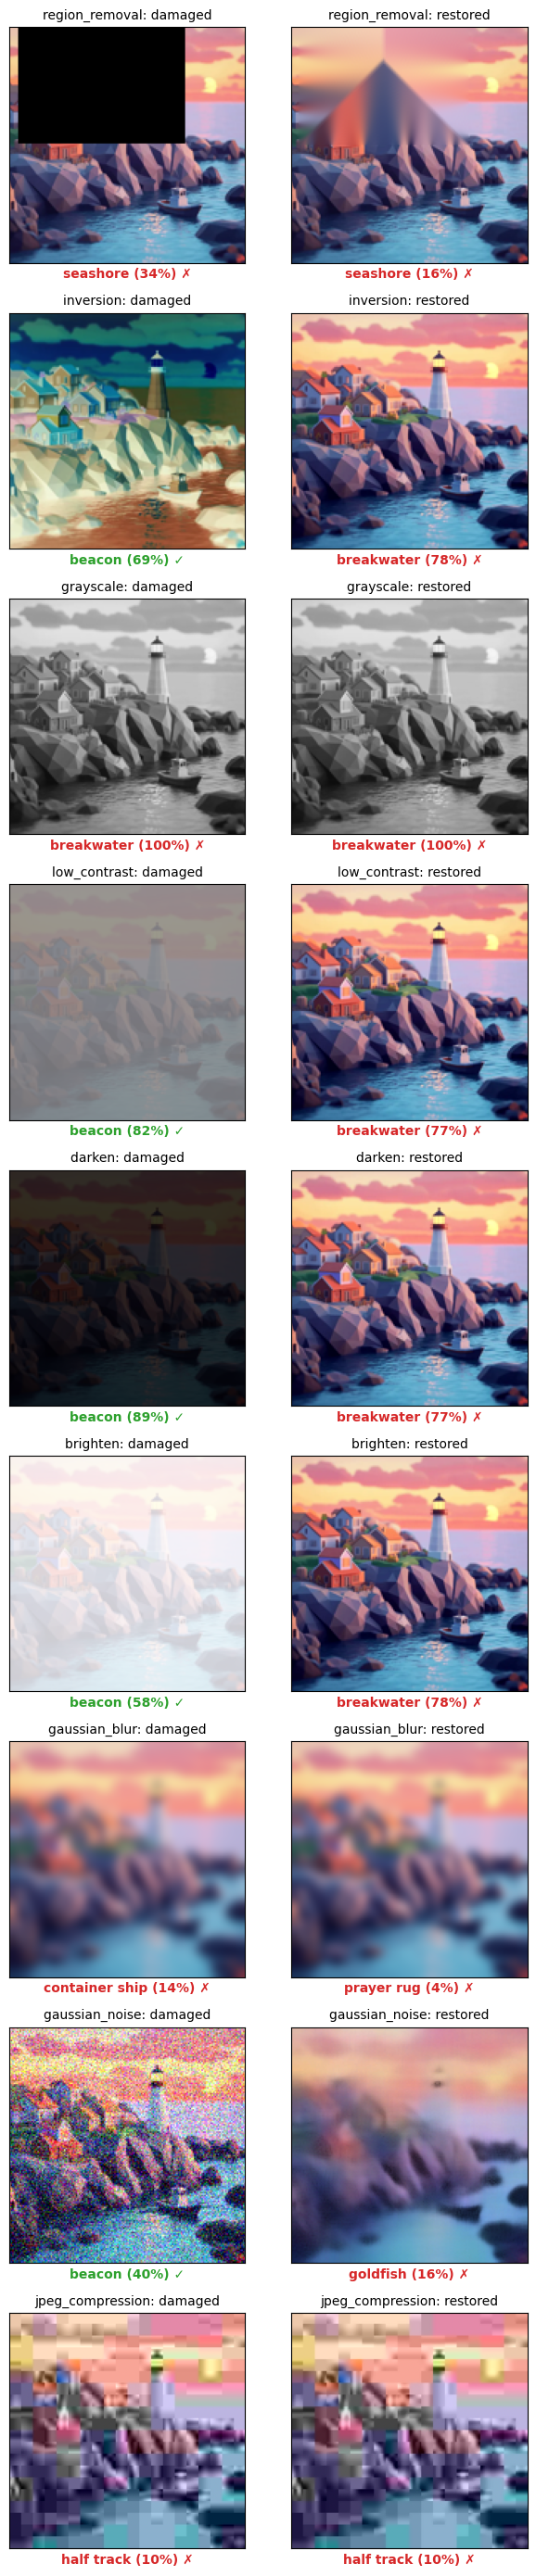

In [8]:
fig, axes = plt.subplots(len(NO_DEPTH), 2, figsize=(6.5, 3.1 * len(NO_DEPTH)))
for k, name in enumerate(NO_DEPTH):
    for j, (im, tag) in enumerate(zip(images[name], ["damaged", "restored"])):
        i = 1 + 2 * k + j
        ok = preds.index[i] == TRUE_IDX
        axes[k, j].imshow(im); axes[k, j].set_xticks([]); axes[k, j].set_yticks([])
        axes[k, j].set_title(f"{name}: {tag}", fontsize=10)
        axes[k, j].set_xlabel(f"{lab(i)} ({preds.confidence[i]:.0%}) {mark(i)}",
                              color="tab:green" if ok else "tab:red", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

## What this shows

- **Even the clean image is "wrong".** ResNet says *breakwater* (72%) and puts *lighthouse* second (23%). The scene really contains both, so with one label per image, top-1 accuracy is a harsh judge here.
- **Lighting damage made it "right".** Low contrast, darkening, brightening and inversion wash out the colourful houses and rocks. The lighthouse silhouette is then the strongest thing left, so ResNet switches to *beacon*.
- **Restoration "hurt" by undoing that.** It brings the image back close to the original, so ResNet goes back to *breakwater*. Restoration did its job (it recovered the original image), but the score went down.
- **This is the reviewer's point.** Getting back to the original prediction isn't the same as getting the right answer, which is why we score against the true label.
- **Noise and blur behave as in the study.** The denoiser smears the scene (beacon → goldfish), and heavy blur leaves nothing to recover.
- **Caveat:** this is one out-of-distribution image (a 3D render, not a photo) with an ambiguous label. It's a good illustration but not evidence. The 500-image results are the evidence.
